## Mini-Project 1: Real Estate & PropTech – Housing Price Prediction

> **Dataset Name:**: House Prices: Advanced Regression Techniques

The dataset contains information related to housing prices. Key columns include:

* `SalePrice`: Property sale price (target variable)
* `GrLivArea`: Above-ground living area (in square feet)
* `BedroomAbvGr`: Number of bedrooms above ground
* `GarageCars`: Garage capacity (number of cars)
* `YearBuilt`: Year the property was built
* `Neighborhood`: Neighborhood where the property is located

### Introductory Level:`
1. Identify missing values and fill numerical columns using the median (via Pandas).

2. Plot the distribution of `SalePrice` and a scatter plot showing its relationship with `GrLivArea` (using Matplotlib and Seaborn).

3. Calculate Pearson correlation coefficients between numerical variables and identify the strongest relationship with the price.

4. Preprocess textual features (such as "neighborhood") using the One-Hot Encoding method.

### Advanced Level:

5. Build a simple Linear Regression model and evaluate it using RMSE and R² metrics.

6. Train Lasso and Ridge models; analyze the impact of regularization penalties on model coefficients and compare the results.

7. Build a Decision Tree Regressor model, limiting the tree depth (max_depth) to prevent overfitting, and compare it with the previous models.

8. Compare the models with a Random Forest Regressor and plot the feature importance.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
#show all columns without truncation
pd.set_option('display.max_columns', None)

#show all rows without truncation
pd.set_option('display.max_rows', None)

#Prevent long string text inside cells from being cut off
pd.set_option('display.max_colwidth', None)

In [51]:
df = pd.read_csv("1-data/train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [53]:
protected_cols = ["GrLivArea" ,'SalePrice']
features_to_check = [col for col in df.columns if col not in protected_cols]

rows with too many unique values

In [54]:
df.dtypes

Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
Street               str
Alley                str
LotShape             str
LandContour          str
Utilities            str
LotConfig            str
LandSlope            str
Neighborhood         str
Condition1           str
Condition2           str
BldgType             str
HouseStyle           str
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle            str
RoofMatl             str
Exterior1st          str
Exterior2nd          str
MasVnrType           str
MasVnrArea       float64
ExterQual            str
ExterCond            str
Foundation           str
BsmtQual             str
BsmtCond             str
BsmtExposure         str
BsmtFinType1         str
BsmtFinSF1         int64
BsmtFinType2         str
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating              str


In [55]:
# 1. Select ONLY text columns
text_cols = df.select_dtypes(include=['str']).columns

# 2. Set a percentage threshold (e.g., drop if unique values > 30% of total rows)
row_count = len(df)
text_cols_to_drop = [col for col in text_cols if (df[col].nunique() / row_count) > 0.30]

# 3. Drop them (SalePrice is 100% safe because it's numeric and wasn't even looked at!)
df = df.drop(columns=text_cols_to_drop)

df.shape

(1460, 81)

Dropping the columns with too many missing values

between 30-50% missing values is considered alot

In [56]:
cols_to_drop = [col for col in df.columns if df[col].isnull().sum() > 700]

df = df.drop(columns=cols_to_drop)

print(f"Deleted columns: {cols_to_drop}, {len(cols_to_drop)} columns")

Deleted columns: ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature'], 5 columns


1. Identify missing values and fill numerical columns using the median.

In [58]:
numeric_cols = df.select_dtypes(include=['number']).columns

#median
for col in numeric_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

2. Plot the distribution of `SalePrice` and a scatter plot showing its relationship with `GrLivArea` (using Matplotlib and Seaborn).Handlng numeric missing values3.

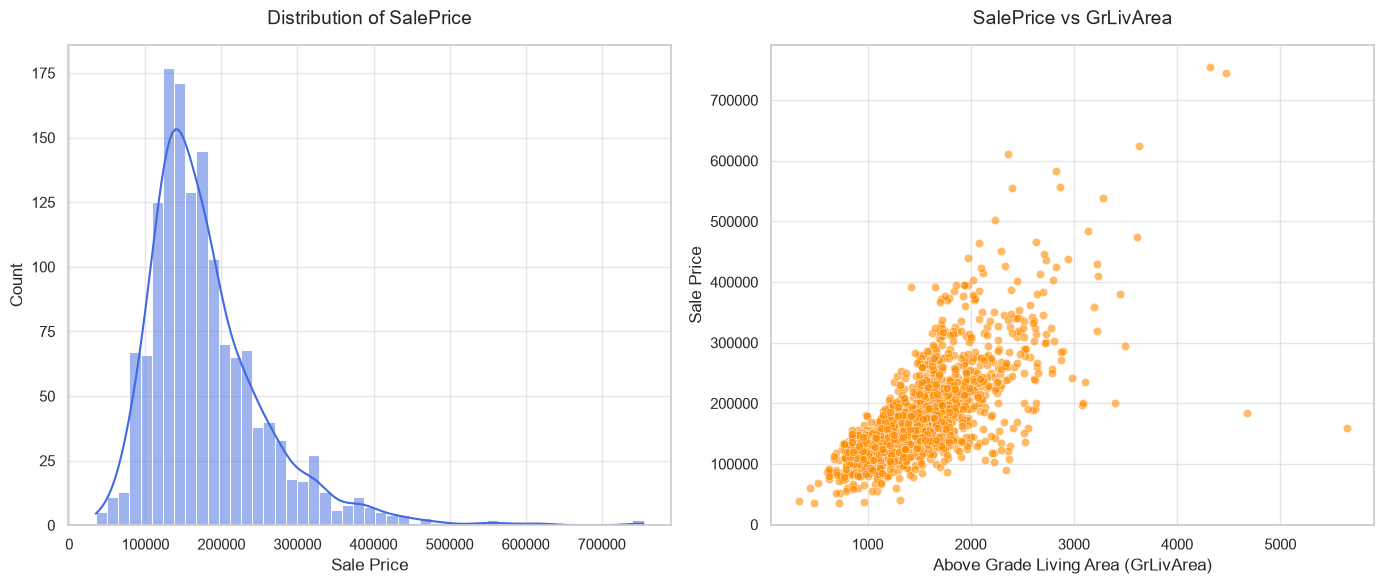

In [60]:
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Draw the Distribution Plot
sns.histplot(data=df, x='SalePrice', kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribution of SalePrice', fontsize=14, pad=15)
axes[0].set_xlabel('Sale Price', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

# Draw the Scatter Plot
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', ax=axes[1], alpha=0.6, color='darkorange')
axes[1].set_title('SalePrice vs GrLivArea', fontsize=14, pad=15)
axes[1].set_xlabel('Above Grade Living Area (GrLivArea)', fontsize=12)
axes[1].set_ylabel('Sale Price', fontsize=12)

plt.tight_layout()
plt.show()


3. Calculate Pearson correlation coefficients between numerical variables and identify the strongest relationship with the price.

In [61]:
# Compute the Pearson correlation matrix
correlation_matrix = df[numeric_cols].corr(method='pearson')

# Sort correlations in descending order
target_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)

print("Pearson correlation with SalePrice:")
print(target_corr)

Pearson correlation with SalePrice:
SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
GarageYrBlt      0.466754
BsmtFinSF1       0.386420
LotFrontage      0.334771
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
Ki

4. Preprocess textual features (such as "neighborhood") using the One-Hot Encoding method.4

In [62]:
# Keep only the top 10 most frequent neighborhoods, mark the rest as 'Rare'
selected_cols = ['SalePrice', 'GrLivArea', 'BedroomAbvGr', 'GarageCars', 'YearBuilt', 'Neighborhood']
df_encoded = df[selected_cols].copy()

top_neighborhoods = df['Neighborhood'].value_counts().index[:10]
df['Neighborhood'] = df['Neighborhood'].apply(lambda x: x if x in top_neighborhoods else 'Rare')

df_encoded = pd.get_dummies(df_encoded, drop_first=True)

print(df_encoded.head())


   SalePrice  GrLivArea  BedroomAbvGr  GarageCars  YearBuilt  \
0     208500       1710             3           2       2003   
1     181500       1262             3           2       1976   
2     223500       1786             3           2       2001   
3     140000       1717             3           3       1915   
4     250000       2198             4           3       2000   

   Neighborhood_Blueste  Neighborhood_BrDale  Neighborhood_BrkSide  \
0                 False                False                 False   
1                 False                False                 False   
2                 False                False                 False   
3                 False                False                 False   
4                 False                False                 False   

   Neighborhood_ClearCr  Neighborhood_CollgCr  Neighborhood_Crawfor  \
0                 False                  True                 False   
1                 False                 False       

### Advanced Level:

5. Build a simple Linear Regression model and evaluate it using RMSE and R² metrics.

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# SPLIT
X = df_encoded.drop(columns=['SalePrice'])
y = df_encoded['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# SIMPLE SCALING
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# FIT THE MODEL
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# PREDICT & EVALUATE
y_pred = model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"R2 Score: {r2:.4f}")
print(f"RMSE: ${rmse:,.2f}")

R2 Score: 0.7883
RMSE: $40,298.22


6. Train Lasso and Ridge models; analyze the impact of regularization penalties on model coefficients and compare the results.

In [65]:
from sklearn.linear_model import Ridge, Lasso

# Ridge model
ridge = Ridge()
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
print("Ridge R2:")
print(r2_score(y_test, ridge_pred))
print("Ridge coefficients:")
print(ridge.coef_)

# Lasso model
lasso = Lasso()
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
print("Lasso R2:")
print(r2_score(y_test, lasso_pred))
print("Lasso coefficients:")
print(lasso.coef_)


Ridge R2:
0.7883484738915286
Ridge coefficients:
[    77.26768364  -8656.302468    16289.48914579    541.50127531
 -22195.55153237 -32637.82242208   3109.07845788  24338.11379997
   8458.00925159  33074.5670115  -15740.0926629   -7950.25061881
  -4437.17992839 -31943.86686049  -9225.2323375   -1517.27546276
 -16281.85775118  -5030.98802401  54328.99682414  70226.21035054
 -12435.57101314  -8280.03757393  -3581.00140776  -6940.69795071
  17432.62096764  69716.58355034  25879.15164121  47759.9389643 ]
Lasso R2:
0.7883410255022515
Lasso coefficients:
[ 7.66364711e+01 -8.68255174e+03  1.61200540e+04  5.37151844e+02
 -3.26889452e+04 -2.47692230e+04  1.33138986e+04  3.64182845e+04
  1.93368967e+04  4.44978412e+04 -5.51763145e+03  2.84829790e+03
  5.43971637e+03 -2.47211225e+04  1.10257467e+03  8.92015266e+03
 -7.89515893e+03  5.74473890e+03  6.74432802e+04  8.25788905e+04
 -2.13804921e+03  1.83038915e+03  6.71565082e+03  3.65217321e+03
  2.86033225e+04  8.42091701e+04  3.77368885e+04  6.3734

7. Build a Decision Tree Regressor model, limiting the tree depth (max_depth) to prevent overfitting, and compare it with the previous models.

In [66]:
from sklearn.tree import DecisionTreeRegressor

# make model with depth 5 so it does not overfit
tree = DecisionTreeRegressor(max_depth=5, random_state=42)
tree.fit(X_train, y_train)

train_p = tree.predict(X_train)
test_p = tree.predict(X_test)

print("Train score:")
print(r2_score(y_train, train_p))
print("Test score:")
print(r2_score(y_test, test_p))

Train score:
0.8058491622766385
Test score:
0.8232172631545486


8. Compare the models with a Random Forest Regressor and plot the feature importance.

Random Forest R2:
0.8850753970097767


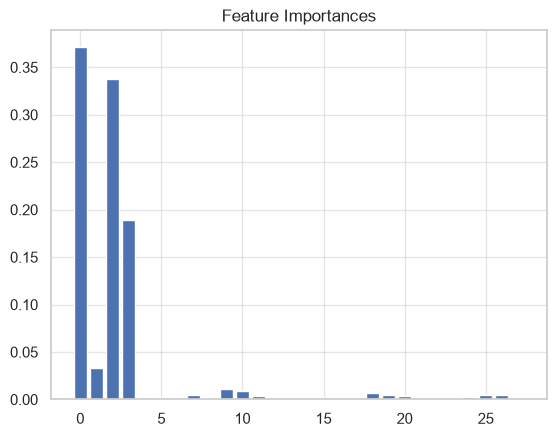

In [67]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest R2:")
print(r2_score(y_test, rf_pred))

# basic plot for importance without sorting them nicely
importances = rf.feature_importances_
plt.bar(range(len(importances)), importances)
plt.title("Feature Importances")
plt.show()